[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Dissolve and Explode


## What you will be able to do

Merge the shapes that share a value into one shape with `dissolve`, decide how every other column is
combined, and split a shape made of several parts into one row per part with `explode`.

## The idea

### The problem

The forecasters work in eight districts, and the regional office reports on three regions: Southern
Norway, which is the South, East, West and Mid districts, Northern Norway, which is the North, Far North
and Northeast districts, and Svalbard. It wants each region's outline for a map, and each region's
number of stations for a table.

Drawing a region's outline by hand means tracing the outside edge of four districts and leaving out
every border they share, hundreds of corners for each region. The station counts have to be added up
district by district, and the region's average elevation has to be computed from the stations. The opposite
question comes up too: Norway's outline is one row whose shape has 31 parts, and asking which part is
the largest island needs each part as a row of its own.

### A formal definition

> **`dissolve`** groups the rows of a GeoDataFrame by the values of a column, merges each group's
> geometries into one geometry with a union, and combines each group's other columns with an
> aggregation function, as `groupby` followed by `agg` does in pandas. **`explode`** works the other
> way for the geometry. It gives every part of a multipart geometry, such as a `MultiPolygon`, a row of
> its own, and repeats the row's other columns on each part.

### Why it works that way

A union of polygons that touch along a border removes that border, so four districts become one
region with a single outside edge. Polygons that do not touch stay separate parts of one
`MultiPolygon`. The region is a new geometry, and its area is measured again from the merged shape.

The other columns need a decision, because one row now stands for several. `dissolve` keeps the
first row's value unless told otherwise, so a count has to be summed on purpose. A district's mean
elevation is a different case, since a region's mean is the mean over all of its stations, which
an average of the district means gives only when every district has the same number of stations,
so the statistic has to come from the stations themselves.

`explode` changes the number of rows, so it changes the index too. By default every part keeps its
original row's label, and `index_parts=True` or `ignore_index=True` gives the parts labels of their
own. `union_all` merges a whole column into one Shapely geometry, which is a shape, with no table
around it.

### Where this shows up

Regions made from districts, counties from municipalities and sales areas from postal codes are all a
dissolve. The **Making Maps** notebook draws regions like these, and the **A Station Atlas** notebook
summarizes the network by district.

### What this notebook covers

- dissolving districts into regions, with the station counts summed
- an average that has to come from the stations
- `dissolve` with no column, and `union_all`
- `explode` and the three ways of labeling the parts
- three mistakes with dissolve and its columns

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import box

cells = gpd.GeoDataFrame({"region": ["west", "west", "east"], "stations": [3, 4, 5]},
                         geometry=[box(0, 0, 1, 1), box(1, 0, 2, 1), box(5, 0, 6, 1)])
regions = cells.dissolve("region", aggfunc="sum")
print(regions.assign(area=regions.area, shape=regions.geom_type).drop(columns="geometry"))
```

```
        stations  area    shape
region
east           5   1.0  Polygon
west           7   2.0  Polygon
```

The two squares of the west region share an edge, so they merge into one rectangle of area 2, and their
stations add up to 7. The east square has no partner and stays as it is.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, Matplotlib for the maps, and
`warnings` for one of the Common errors.

- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `warnings` catches the warning that the first Common error shows
- `numpy` and `pandas` build the made-up register of stations
- `geopandas` does the dissolving and exploding, and the cell prints its version
- `shapely` is the geometry library under GeoPandas, used here to build the districts
- `matplotlib.pyplot` draws the maps

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden. Made with Natural Earth.
The outlines come from Natural Earth's 1:50m map of the world's countries, which is in the public
domain.

`stations` is the register of 300 weather stations as a GeoDataFrame in latitude and longitude, and
`districts` is the eight forecast districts in UTM zone 33N, whose unit is the meter. Both are made up.
The stations are drawn at random over mainland Norway from a fixed seed, and the districts are drawn
around eight chosen centers and cut to Norway's outline. `REGIONS` names the region of every district.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)

districts = forecast_districts()
REGIONS = {"South": "Southern Norway", "East": "Southern Norway", "West": "Southern Norway",
           "Mid": "Southern Norway", "North": "Northern Norway", "Far North": "Northern Norway",
           "Northeast": "Northern Norway", "Svalbard": "Svalbard"}
print("geopandas", gpd.__version__, "|", len(countries), "countries,", len(stations), "made-up stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | 5 countries, 300 made-up stations, 8 made-up districts


## Worked examples

### The districts, their regions and their stations

A spatial join gives every station its district, and a count by district goes into the districts'
table beside a column naming each district's region.

In [2]:
placed = gpd.sjoin(stations.to_crs(districts.crs), districts, how="left").drop(columns="index_right")
district_counts = placed.groupby("district").size().reindex(districts["district"], fill_value=0)

district_table = districts.assign(
    region=districts["district"].map(REGIONS),
    stations=district_counts.to_numpy(),
    area_km2=(districts.area / 1e6).round(0).astype(int),
)
district_table.drop(columns="geometry")

,district,region,stations,area_km2
0,South,Southern Norway,32,36056
1,East,Southern Norway,56,62504
2,West,Southern Norway,43,53904
3,Mid,Southern Norway,69,61575
4,North,Northern Norway,27,30984
5,Far North,Northern Norway,25,31283
6,Northeast,Northern Norway,48,48523
7,Svalbard,Svalbard,0,62068


Every district has a region, and Svalbard is a region of one district with no stations, since every
station in the register is on the mainland.

### Districts dissolved into regions

`dissolve("region")` groups the rows by region and merges each group's shapes. The `aggfunc`
dictionary says how to combine the other columns. The station counts are summed, and `count` gives
the number of districts in each region.

In [3]:
regions = district_table.dissolve("region", aggfunc={"stations": "sum", "district": "count"})
regions["area_km2"] = (regions.area / 1e6).round(0).astype(int)
regions.assign(shape=regions.geom_type).drop(columns="geometry")

,stations,district,area_km2,shape
region,,,,
Northern Norway,100,3,110790,MultiPolygon
Southern Norway,200,4,214039,MultiPolygon
Svalbard,0,1,62068,MultiPolygon


The region names become the index, as `groupby` makes them. Southern Norway has 200 stations in four
districts and Northern Norway 100 in three. The areas were measured again from the merged shapes:
214,039 km² for Southern Norway, which is the four districts' 36,056, 62,504, 53,904 and 61,575
added up. Each region is a `MultiPolygon`, because each has islands that touch no other part.

A map shows the borders that the union removed.

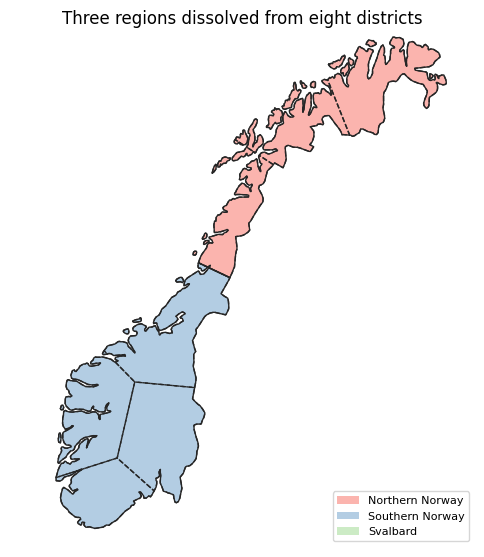

In [4]:
fig, ax = plt.subplots(figsize=(6, 7))
regions.reset_index().plot(ax=ax, column="region", categorical=True, cmap="Pastel1",
                           legend=True, legend_kwds={"loc": "lower right", "fontsize": 8})
districts.boundary.plot(ax=ax, color="0.15", linewidth=1, linestyle="--")
regions.boundary.plot(ax=ax, color="0.15", linewidth=1)
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Three regions dissolved from eight districts")
plt.show()

The solid lines are the regions' outlines, drawn last so that they cover the districts' borders
where the two run together along the coast. The dashed lines are the districts' borders that now lie
inside a region. Svalbard is off the top of the map.

### An average that comes from the stations

The districts' table has no elevation, and a district's mean elevation could be added to it and then
averaged, as `dissolve` with `aggfunc="mean"` would. The cell computes both that average of district means and the mean over
every station in the region, from `placed`, which has a row per station.

In [5]:
district_means = placed.groupby("district")["elevation_m"].mean()
mean_of_means = district_means.groupby(district_means.index.map(REGIONS)).mean()
station_means = placed.groupby(placed["district"].map(REGIONS))["elevation_m"].mean()

pd.DataFrame({"mean of district means": mean_of_means, "mean over stations": station_means}).rename_axis("region").round(1)

,mean of district means,mean over stations
region,,
Northern Norway,363.8,366.9
Southern Norway,357.7,361.0


The two columns disagree in both regions, 363.8 against 366.9 meters in Northern Norway and 357.7
against 361.0 in Southern Norway. An average of district means gives each district the same weight,
so the Far North district's 25 stations count as much as the Northeast district's 48. A region's mean
elevation comes from the stations, with a `groupby` on the region, and can then be joined to the
regions' table. Svalbard has no row, since no station is in it.

### Dissolving every row into one shape with `union_all`

`dissolve()` with no column puts every row in one group. `union_all` does the same merge on a
GeoSeries and returns the shape alone. The countries reach 42 degrees east, 27 degrees from the
middle of UTM zone 33N, where UTM's areas grow too large, so the union is measured in EPSG:3035, the
equal-area CRS for Europe.

In [6]:
whole = districts.dissolve()
print(type(whole).__name__, "| rows:", len(whole), "| area:", round(whole.area.iloc[0] / 1e6), "km²")
norway_km2 = countries[countries["ADMIN"] == "Norway"].to_crs(25833).area.iloc[0] / 1e6
print("Norway's outline:", round(norway_km2), "km²")

nordic = countries.to_crs(3035).union_all()
print(type(nordic).__name__, "| parts:", len(nordic.geoms), "| area:", round(nordic.area / 1e6), "km²")

GeoDataFrame | rows: 1 | area: 386897 km²
Norway's outline: 386897 km²
MultiPolygon | parts: 57 | area: 2328391 km²


The eight districts dissolve back into one row of 386,897 km², the area of Norway's outline, since
the districts were cut from it. The five countries merge into a single `MultiPolygon` of 57 parts,
and the result is a Shapely geometry with no CRS of its own and no columns, which is what a later
step needs when the shape is a tool, such as the land to measure against.

### `explode` and its index

Norway's outline is one row. `explode` gives each of its parts a row.

In [7]:
norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833)
parts = norway.explode()
print("rows before:", len(norway), "| rows after:", len(parts))
print("labels:", parts.index[:4].tolist())
print("rows labeled 2:", len(parts.loc[2]))
print("shapes:", parts.geom_type.unique().tolist())

rows before: 1 | rows after: 31
labels: [2, 2, 2, 2]
rows labeled 2: 31
shapes: ['Polygon']


The 31 parts are each a `Polygon`, and every one keeps the label of the row it came from, 2, so a
`.loc[2]` would return all 31. The other two options give the parts labels of their own.

In [8]:
print(norway.explode(index_parts=True).index[:3].tolist())
print(norway.explode(ignore_index=True).index[:3].tolist())

[(2, 0), (2, 1), (2, 2)]
[0, 1, 2]


`index_parts=True` labels each part with a pair, the original row and the part's number within it.
`ignore_index=True` numbers the parts from 0, as a new table would be numbered.

### The largest parts of Norway

In [9]:
islands = norway.explode(ignore_index=True)
islands["area_km2"] = (islands.area / 1e6).round(0).astype(int)
islands["north_of_74"] = islands.geometry.bounds["miny"] > 8_200_000
print(islands.nlargest(3, "area_km2")[["area_km2", "north_of_74"]])
print("parts north of 74 degrees:", islands["north_of_74"].sum())

    area_km2  north_of_74
0     312895        False
27     38807         True
26     14769         True
parts north of 74 degrees: 9


The mainland is the largest part at 312,895 km². The next two lie north of 74 degrees, so they are
islands of Svalbard, 38,807 and 14,769 km², and 9 of the 31 parts are Svalbard's. The test uses the
northing, 8,200,000 meters, which is about 74 degrees north in UTM zone 33N.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/11-dissolve-and-explode-solutions.ipynb).

**1.** Dissolve `district_table` into regions with the total area of each region's districts, by summing `area_km2`, and print it beside the area measured from the merged shapes.

In [10]:
# your code here

**2.** Print the number of parts in each of the three regions in `regions`, using `explode` and a count by region.

In [11]:
# your code here

**3.** Print the mean installation year of the stations in each region, computed from `placed`.

In [12]:
# your code here

**4.** Explode Sweden's outline in UTM zone 33N and print the number of parts and the area of the largest part in square kilometers.

In [13]:
# your code here

**5.** Make a GeoDataFrame of the parts of `nordic`, the union of the five countries, and print the five largest areas in square kilometers.

In [14]:
# your code here

## Common errors

### `DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.`

Examples written for older GeoPandas use the attribute `unary_union`. Python hides a library's
deprecation warnings from a notebook by default, so the cell turns them on to show it.

In [15]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", DeprecationWarning)
    merged = countries.unary_union
for warning in caught:
    print(f"{warning.category.__name__}: {str(warning.message).splitlines()[0]}")
print(merged.geom_type)
print("same as union_all():", merged.equals(countries.union_all()))

MultiPolygon
same as union_all(): True


The attribute still works in GeoPandas 1.2, and returns the same `MultiPolygon` as `union_all()`, but
it is deprecated, so a later release can remove it. Call the method, `countries.union_all()`, as the
worked examples do.

### No error, and each region's station count from one district

In [16]:
table = districts.assign(region=districts["district"].map(REGIONS), stations=district_counts.to_numpy())
table.dissolve("region").drop(columns="geometry")

,district,stations
region,,
Northern Norway,North,27
Southern Norway,South,32
Svalbard,Svalbard,0


With no `aggfunc`, `dissolve` keeps each group's first value. Northern Norway shows 27 stations, the
North district's, and Southern Norway 32, the South district's, where the regions hold 100 and 200.
The `district` column shows one district per region for the same reason. Name what each column needs,
as the worked examples did with `aggfunc={"stations": "sum", "district": "count"}`.

### No error, and district names run together

In [17]:
table.dissolve("region", aggfunc="sum").drop(columns="geometry")

,district,stations
region,,
Northern Norway,NorthFar NorthNortheast,100
Southern Norway,SouthEastWestMid,200
Svalbard,Svalbard,0


`aggfunc="sum"` applies to every column, and pandas sums text by joining it, so Northern Norway's
district reads `NorthFar NorthNortheast`. The station counts are right this time. A column of
averages would be added up too, and for a region of several districts that sum is not an average. A dictionary limits each function
to the columns it suits.

In [18]:
table.dissolve("region", aggfunc={"stations": "sum", "district": "count"}).drop(columns="geometry")

,stations,district
region,,
Northern Norway,100,3
Southern Norway,200,4
Svalbard,0,1


## Recap

- You can dissolve polygons that share a value into one shape per value, with the borders between
  them removed.
- You can choose how each other column is combined with an `aggfunc` dictionary.
- You can compute an average for a dissolved region from the rows it covers.
- You can merge a whole column with `union_all`, and split multipart shapes into rows with `explode`.

## What is next

The **Making Maps** notebook draws districts, regions and stations as maps, with colors chosen from the
data.

---

&#8592; **Previous:** [Buffers, Overlays and Clipping](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/10-buffers-overlays-and-clipping.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [Making Maps](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/12-making-maps.ipynb) &#8594;
